# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Demo Notebook: Interactive Visualization, Visual Analytics and Sensemaking

topics:

1. Interactive Visualization Concepts: Why Change a View? (Munzner's five options)
2. Purpose of Interaction and the Interactive Loop
3. Brushing (interactive)
4. Cross-View Brushing, Linking and Coordinated Views
5. Numerical 1: Overview–Detail Zoom Scaling
6. Filtering and Dynamic Queries (interactive slider)
7. Numerical 2: Dynamic-Query Response-Time Budget
8. Selection and Highlighting
9. Zooming, Panning and Semantic Zoom (+ Numerical 3)
10. Details-on-Demand and Tooltips (interactive)
11. Drill-Down (interactive)
12. Animated Transitions (interactive)
13. Focus + Context: Degree-of-Interest and Elision
14. Focus + Context: Fisheye Distortion (+ Numerical 4)
15. Overview First, Zoom and Filter, Details-on-Demand: An Interaction Sequence
16. Interactive Temporal Visualization (interactive range slider)
17. Visual Analytics and Human-in-the-Loop Analysis
18. Exploratory Analysis and Pattern Discovery by Reordering
19. Anomaly Detection: Precision, Recall and F1 (+ Numerical 5)
20. Hypothesis Generation and Testing (and Confirmation Bias)
21. Sensemaking, Information Foraging and Scented Widgets (+ Numerical 6)
22. Iterative Analytical Reasoning, Provenance and a Visual-Analytics Workflow

**Dataset:** `unit3_ppt7_card_transactions.csv` — 30 days of **card transactions** at a payments company (5,520 rows; synthetic but realistic).
Each row: `timestamp`, `day`, `hour`, `customer_id`, `city`, `merchant_category`, `amount_inr`,
`distance_from_home_km`, an automated fraud **`detector_score`** (0–1) and `is_fraud` — whether the case was
**confirmed** as fraud by the investigations team. Fraud is rare (~2%), so this is a needle-in-a-haystack problem: the
natural home of interactive visual analytics.

**Interactive cells** use plotly: you can zoom (drag), pan (shift-drag / pan tool), hover for tooltips, box/lasso-select,
click legend entries, and use sliders/buttons. Re-run a cell if a figure appears blank.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions, {tx.is_fraud.sum()} confirmed fraud ({tx.is_fraud.mean():.1%}), "
      f"{tx.city.nunique()} cities, {tx.merchant_category.nunique()} merchant categories")
tx.head()

5,520 transactions, 120 confirmed fraud (2.2%), 6 cities, 8 merchant categories


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## 1. Interactive Visualization Concepts: Why Change a View?  *(Slides 4–5)*

**What:** Interaction turns a static picture into a tool for exploration — the view **changes over time in response to
input** (the key advantage of a screen over paper). Datasets are too large to show everything, so Munzner lists five
(combinable) options: **derive** new data, **change the view over time**, **facet** into multiple views, **reduce**
(filter/aggregate), **embed** focus + context.

**Why:** Below, a raw "show everything" scatter (5,520 overplotted points) next to one example of each option applied
to the same data. Interaction is what lets an analyst move between them.

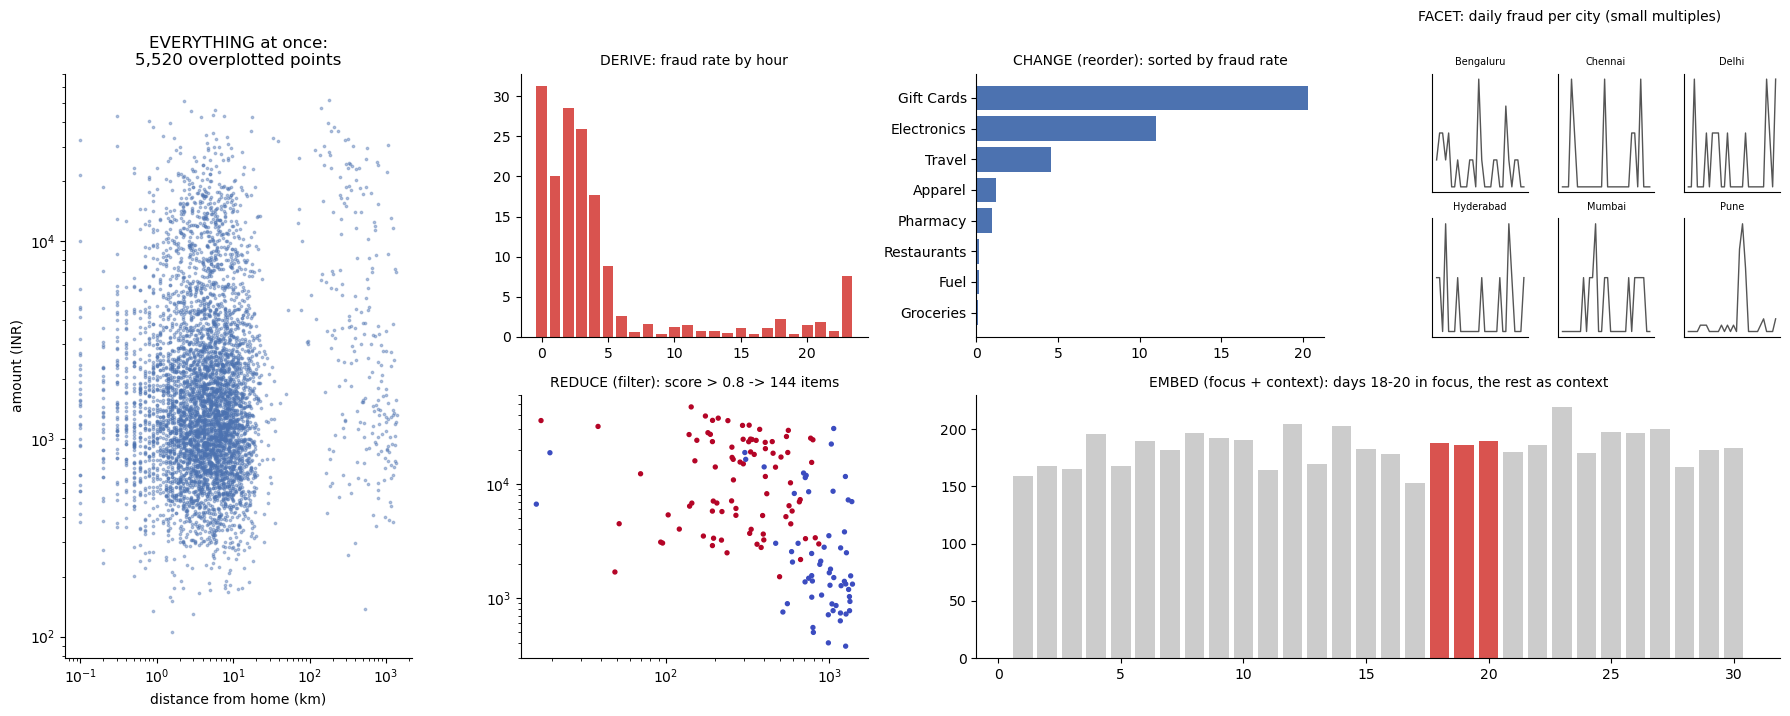

In [2]:
fig = plt.figure(figsize=(18, 7))
gs = fig.add_gridspec(2, 4)
ax = fig.add_subplot(gs[:, 0])
ax.scatter(tx.distance_from_home_km, tx.amount_inr, s=3, alpha=0.4, c="#4C72B0")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("distance from home (km)"); ax.set_ylabel("amount (INR)")
ax.set_title("EVERYTHING at once:\n5,520 overplotted points")

ax = fig.add_subplot(gs[0, 1]); rate = tx.groupby("hour").is_fraud.mean() * 100
ax.bar(rate.index, rate.values, color="#D9534F"); ax.set_title("DERIVE: fraud rate by hour", fontsize=10)
ax = fig.add_subplot(gs[0, 2]); srt = tx.groupby("merchant_category").is_fraud.mean().sort_values() * 100
ax.barh(srt.index, srt.values, color="#4C72B0"); ax.set_title("CHANGE (reorder): sorted by fraud rate", fontsize=10)
sub = gs[0, 3].subgridspec(2, 3)
for k, city in enumerate(sorted(tx.city.unique())):
    a_ = fig.add_subplot(sub[k // 3, k % 3]); c_ = tx[tx.city == city].groupby("day").is_fraud.sum()
    a_.plot(c_.index, c_.values, color="#555555", lw=1); a_.set_title(city, fontsize=7); a_.set_xticks([]); a_.set_yticks([])
ax = fig.add_subplot(gs[1, 1]); f_ = tx[tx.detector_score > 0.8]
ax.scatter(f_.distance_from_home_km, f_.amount_inr, s=8, c=f_.is_fraud, cmap="coolwarm")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"REDUCE (filter): score > 0.8 -> {len(f_)} items", fontsize=10)
ax = fig.add_subplot(gs[1, 2:]); dd = tx.groupby("day").size()
ax.bar(dd.index, dd.values, color=["#D9534F" if 18 <= d_ <= 20 else "#cccccc" for d_ in dd.index])
ax.set_title("EMBED (focus + context): days 18-20 in focus, the rest as context", fontsize=10)
fig.text(0.875, 1.0, "FACET: daily fraud per city (small multiples)", fontsize=10, ha="center")
plt.tight_layout(); plt.show()

## 2. Purpose of Interaction and the Interactive Loop  *(Slides 6–7)*

**What:** Interaction overcomes display limits, supports open-ended tasks and lets **the view do the remembering** (eyes
beat memory). Interactive visualization is a **closed loop**: user acts → system updates the view → user perceives and
interprets → acts again. **Low latency** is essential (Shneiderman: ~0.1 s feels instantaneous).

**Why:** Below, the same overplotted scatter made *interactive*: drag to zoom into the high-amount, far-from-home corner,
double-click to reset, hover for values. We also time one cycle of the loop (filter + recompute) to show it fits easily
within 0.1 s for this data size.

In [3]:
fig = px.scatter(tx, x="distance_from_home_km", y="amount_inr", color="label", log_x=True, log_y=True, opacity=0.5,
                 color_discrete_map={"legitimate": "#9bb7d4", "confirmed fraud": "#D9534F"},
                 title="Drag a box to zoom, double-click to reset, hover for values", height=480)
fig.update_traces(marker_size=5)
fig.show()

t0 = time.perf_counter()
for _ in range(100):
    sel = tx[(tx.amount_inr > 5000) & (tx.distance_from_home_km > 100)]
    summary = sel.groupby("merchant_category").is_fraud.mean()
loop_ms = (time.perf_counter() - t0) / 100 * 1000
print(f"One filter + aggregate cycle on {len(tx):,} rows: {loop_ms:.2f} ms  (budget for 'instant' feedback: 100 ms)")

One filter + aggregate cycle on 5,520 rows: 2.45 ms  (budget for 'instant' feedback: 100 ms)


## 3. Brushing  *(Slide 8)*

**What:** **Brushing** (Becker & Cleveland 1987): the user paints a selection directly over marks by dragging a
rectangle or freeform lasso; every mark it touches joins the selection and is immediately highlighted.

**Why:** Below, an interactive scatter in **lasso/box-select mode** — drag around any cluster; selected points stay
bright and the rest fade. Try brushing the night-time, long-distance corner (top-right) and notice how red it is.

In [4]:
fig = px.scatter(tx, x="hour", y="distance_from_home_km", color="label", log_y=True, opacity=0.6,
                 color_discrete_map={"legitimate": "#9bb7d4", "confirmed fraud": "#D9534F"},
                 hover_data=["txn_id", "city", "merchant_category", "amount_inr"],
                 title="Brushing: drag a box or lasso (toolbar) to select; double-click to clear", height=480)
fig.update_traces(marker_size=5, unselected_marker_opacity=0.08)
fig.update_layout(dragmode="lasso")
fig.update_xaxes(range=[-0.5, 23.5])
fig.show()

## 4. Cross-View Brushing, Linking and Coordinated Views  *(Slides 9–12)*

**What:** **Cross-view brushing / linked highlighting**: a selection in one view is propagated to every coordinated view,
showing how a region contiguous in one view is *distributed* in the others. **Linking** can share encoding,
highlighting, data (overview–detail, small multiples) or navigation. Juxtaposed views spread information over **space**
instead of time — at the cost of splitting the pixels.

**Why:** Below, a coordinated 4-view layout driven by a brush function. We "move the brush" twice — first over
night-time transactions, then over far-from-home transactions — and every view updates with the same highlight. The
second brush reveals what neither single view could: the brushed items are concentrated in Electronics / Gift Cards and
in Pune.

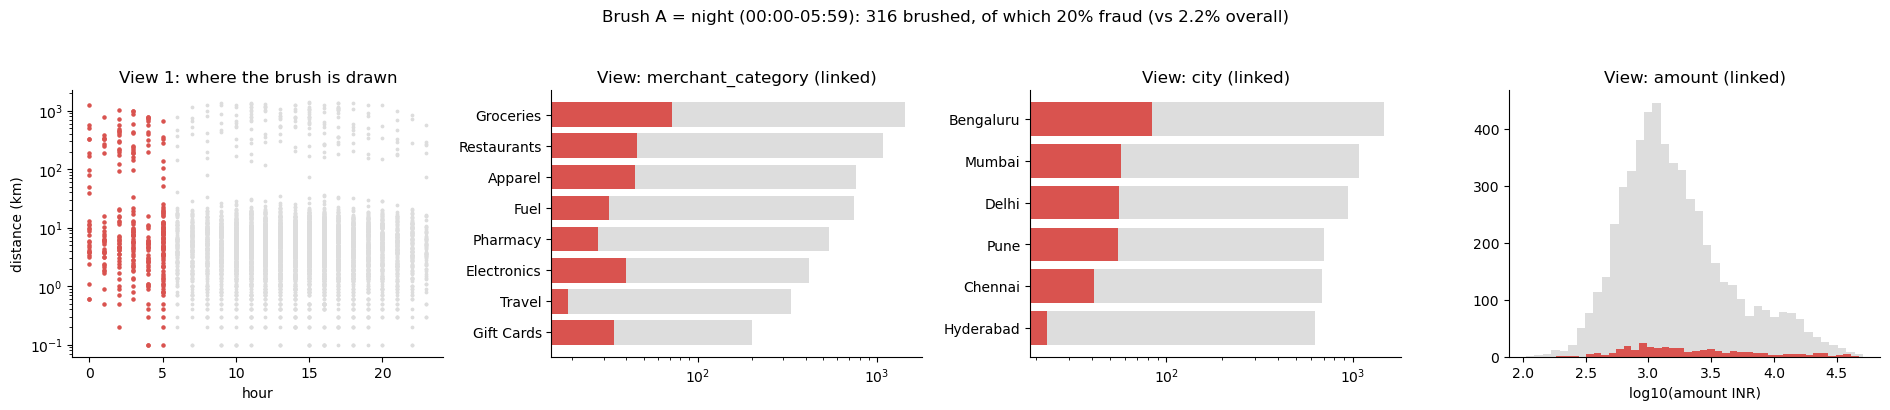

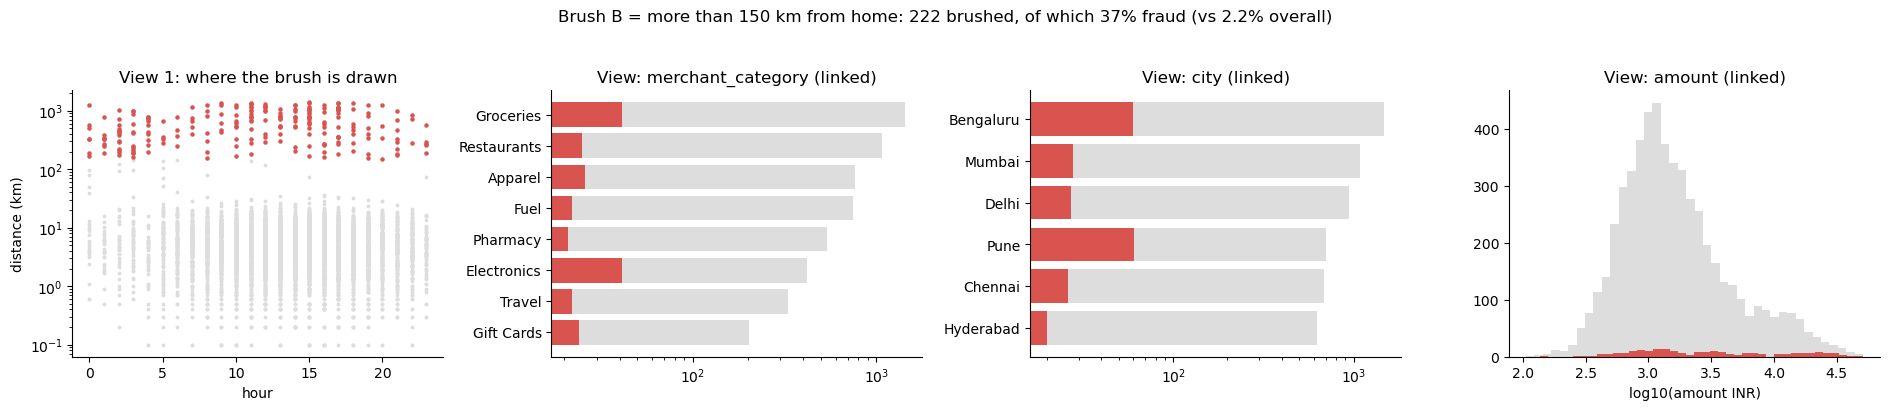

In [5]:
def linked_views(brush, title):
    fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))
    for ax, (x, y, lx, ly) in zip(axes[:1], [("hour", "distance_from_home_km", "hour", "distance (km)")]):
        ax.scatter(tx[x][~brush], tx[y][~brush], s=3, c="#dddddd"); ax.scatter(tx[x][brush], tx[y][brush], s=5, c="#D9534F")
        ax.set_yscale("log"); ax.set_xlabel(lx); ax.set_ylabel(ly); ax.set_title("View 1: where the brush is drawn")
    for ax, col in zip(axes[1:3], ["merchant_category", "city"]):
        allc = tx[col].value_counts(); bc = tx.loc[brush, col].value_counts().reindex(allc.index, fill_value=0)
        ax.barh(allc.index, allc.values, color="#dddddd"); ax.barh(bc.index, bc.values, color="#D9534F")
        ax.set_title(f"View: {col} (linked)"); ax.invert_yaxis(); ax.set_xscale("log")
    axes[3].hist(np.log10(tx.amount_inr), bins=40, color="#dddddd"); axes[3].hist(np.log10(tx.amount_inr[brush]), bins=40, color="#D9534F")
    axes[3].set_xlabel("log10(amount INR)"); axes[3].set_title("View: amount (linked)")
    fig.suptitle(f"{title}: {brush.sum()} brushed, of which {tx.is_fraud[brush].mean():.0%} fraud (vs {tx.is_fraud.mean():.1%} overall)", y=1.04)
    plt.tight_layout(); plt.show()

linked_views(tx.hour < 6, "Brush A = night (00:00-05:59)")
linked_views(tx.distance_from_home_km > 150, "Brush B = more than 150 km from home")

## 5. Numerical 1: Overview–Detail Zoom Scaling  *(Slide 13)*

**What:** Overview panel 300 × 200 px shows 60 km × 40 km. (a) scale = 60/300 = 0.2 km/px; (b) a 900 × 600 px detail panel
at the same scale covers 180 × 120 km; (c) showing 6 × 4 km in 900 px needs 6/900 = 0.00667 km/px → zoom = 0.2/0.00667 =
**30×**.

**Why:** Solved in code, and visualized as an overview–detail pair with the detail extent drawn on the overview.

(a) overview scale = 60/300 = 0.20 km/px
(b) detail panel at zoom 1 covers 180 km x 120 km
(c) 6 km over 900 px = 0.00667 km/px -> zoom factor = 30x


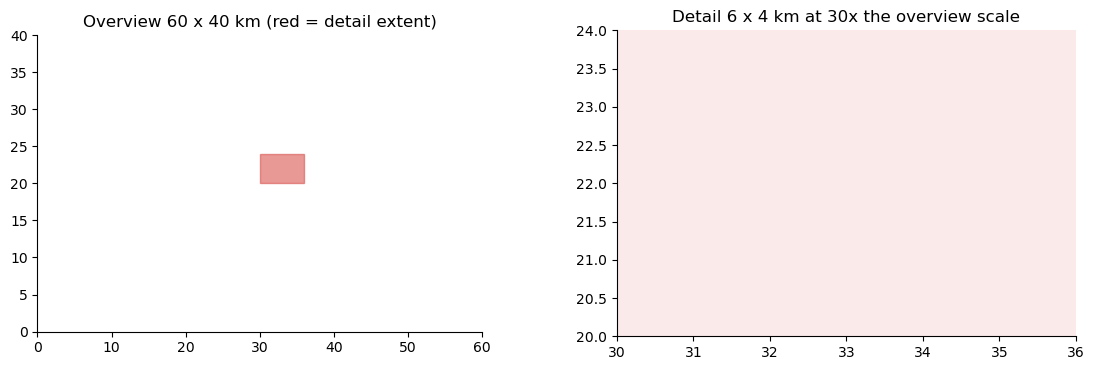

In [6]:
ov_px, ov_km = (300, 200), (60, 40)
scale = ov_km[0] / ov_px[0]
det_px = (900, 600)
print(f"(a) overview scale = {ov_km[0]}/{ov_px[0]} = {scale:.2f} km/px")
print(f"(b) detail panel at zoom 1 covers {det_px[0]*scale:.0f} km x {det_px[1]*scale:.0f} km")
need = 6 / det_px[0]
print(f"(c) 6 km over 900 px = {need:.5f} km/px -> zoom factor = {scale/need:.0f}x")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].set_xlim(0, 60); axes[0].set_ylim(0, 40); axes[0].add_patch(plt.Rectangle((30, 20), 6, 4, color="#D9534F", alpha=0.6))
axes[0].set_title("Overview 60 x 40 km (red = detail extent)"); axes[0].set_aspect("equal")
axes[1].set_xlim(30, 36); axes[1].set_ylim(20, 24); axes[1].set_aspect("equal"); axes[1].set_facecolor("#fbeaea")
axes[1].set_title("Detail 6 x 4 km at 30x the overview scale")
plt.tight_layout(); plt.show()

## 6. Filtering and Dynamic Queries  *(Slides 14–15)*

**What:** **Filtering** removes items (rows) or attributes (columns) outside a condition; what remains keeps full detail.
**Dynamic queries** (FilmFinder, Ahlberg & Shneiderman 1994) tightly couple widgets and display: the view updates
*immediately* as a slider moves — ideal for browsing an unfamiliar dataset without knowing what range to type.

**Why:** Below, an interactive **dynamic-query slider** on the detector score. Drag it: the scatter, the item count and the
fraud share in the title update instantly — a direct-manipulation replacement for re-typing SQL queries.

In [7]:
thresholds = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95]
fig = go.Figure()
for i, th in enumerate(thresholds):
    s = tx[tx.detector_score >= th]
    fig.add_trace(go.Scattergl(x=s.distance_from_home_km, y=s.amount_inr, mode="markers", visible=(i == 0),
                               marker=dict(size=5, color=np.where(s.is_fraud == 1, "#D9534F", "#9bb7d4"), opacity=0.6),
                               text=s.txn_id + " | " + s.city + " | " + s.merchant_category, hoverinfo="text", name=f">= {th}"))
steps = []
for i, th in enumerate(thresholds):
    s = tx[tx.detector_score >= th]
    steps.append(dict(method="update", label=f"{th}",
                      args=[{"visible": [j == i for j in range(len(thresholds))]},
                            {"title": f"Dynamic query: detector_score >= {th} -> {len(s):,} transactions, {s.is_fraud.mean():.0%} fraud"}]))
fig.update_layout(sliders=[dict(active=0, steps=steps, currentvalue={"prefix": "min detector score: "})],
                  title=f"Dynamic query: detector_score >= 0.0 -> {len(tx):,} transactions, {tx.is_fraud.mean():.0%} fraud",
                  xaxis=dict(type="log", title="distance from home (km)"), yaxis=dict(type="log", title="amount (INR)"),
                  height=520, showlegend=False)
fig.show()

## 7. Numerical 2: Dynamic-Query Response-Time Budget  *(Slide 16)*

**What:** Feedback must arrive within **0.1 s** to feel instant. At 2 µs per item: (a) max items = 100,000 µs / 2 µs =
**50,000**; (b) 500,000 items take **1.0 s**; (c) to get back under budget, ≥ **450,000 items (90%)** must be skipped via
indexing / pre-filtering.

**Why:** The slide answers in code — then the same reasoning with a *measured* per-item cost on this machine.

In [8]:
budget_us, cost_us = 100_000, 2
print(f"(a) max items = {budget_us}/{cost_us} = {budget_us // cost_us:,}")
print(f"(b) 500,000 items x {cost_us} us = {500_000 * cost_us / 1e6:.1f} s")
print(f"(c) must skip >= {500_000 - budget_us // cost_us:,} items ({1 - (budget_us // cost_us) / 500_000:.0%})")

big = pd.concat([tx] * 200, ignore_index=True)                   # 1.1 million rows
t0 = time.perf_counter(); _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]; dt = time.perf_counter() - t0
per_item_us = dt / len(big) * 1e6
print(f"\nMeasured here: {len(big):,} rows filtered in {dt*1000:.0f} ms -> {per_item_us:.3f} us/item "
      f"-> max rows within 0.1 s ~ {0.1 / (dt / len(big)):,.0f}")

(a) max items = 100000/2 = 50,000
(b) 500,000 items x 2 us = 1.0 s
(c) must skip >= 450,000 items (90%)

Measured here: 1,104,000 rows filtered in 29 ms -> 0.027 us/item -> max rows within 0.1 s ~ 3,770,106


## 8. Selection and Highlighting  *(Slides 17–18)*

**What:** **Selection** chooses elements (items, links, attributes, views); its output is usually the input of the next
action. **Highlighting** is its visual side. Options: **colour** change (most common, but temporarily hides existing colour
coding), **outline** (preserves colour coding), **size/linewidth**, or **motion** (Ware & Bobrow 2004 — can beat the
others). The highlight must truly **pop out**.

**Why:** Below, the same 12 selected transactions highlighted three ways on a scatter that already uses colour for
merchant category. Colour highlighting destroys the category coding; outline and size keep it.

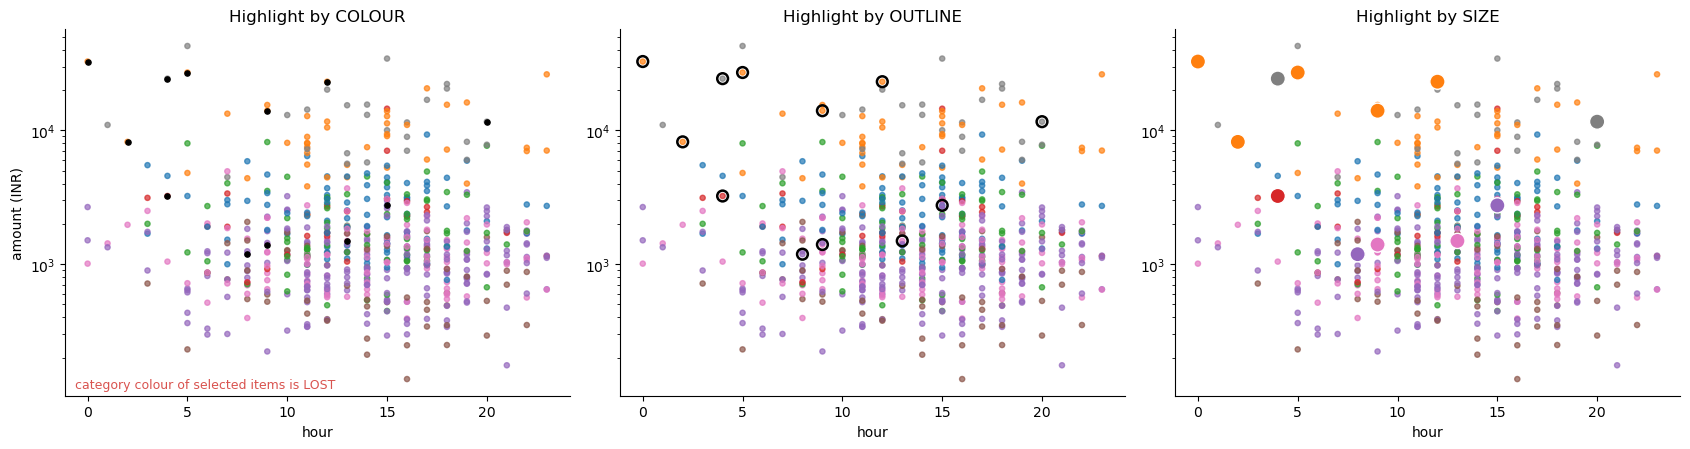

In [9]:
sample = tx.sample(600, random_state=2)
selected = sample.nlargest(12, "detector_score")
cats = sorted(tx.merchant_category.unique()); cmap = dict(zip(cats, plt.cm.tab10.colors))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, mode in zip(axes, ["colour", "outline", "size"]):
    ax.scatter(sample.hour, sample.amount_inr, s=14, c=[cmap[c] for c in sample.merchant_category], alpha=0.7)
    if mode == "colour":
        ax.scatter(selected.hour, selected.amount_inr, s=14, c="black")
    elif mode == "outline":
        ax.scatter(selected.hour, selected.amount_inr, s=60, facecolors="none", edgecolors="black", linewidths=1.8)
    else:
        ax.scatter(selected.hour, selected.amount_inr, s=120, c=[cmap[c] for c in selected.merchant_category], edgecolors="white")
    ax.set_yscale("log"); ax.set_xlabel("hour"); ax.set_title(f"Highlight by {mode.upper()}")
axes[0].set_ylabel("amount (INR)")
axes[0].text(0.02, 0.02, "category colour of selected items is LOST", transform=axes[0].transAxes, fontsize=9, color="#D9534F")
plt.tight_layout(); plt.show()

## 9. Zooming, Panning and Semantic Zoom  *(Slides 19–21)*

**What:** **Geometric zoom** scales everything uniformly — zooming in effectively *filters* (fewer items, more detail),
zooming out *aggregates*. **Panning** translates the camera at fixed zoom. **Semantic zoom** changes the
*representation* as the available pixels change (LiveRAC): colour-only cells (≥ 4 px), sparklines (≥ 40 px), full charts
with axes (≥ 120 px).

**Why:** Numerical 3 solved in code, then a LiveRAC-style city × day grid rendered at three panel widths — the
representation of every cell switches automatically with the pixels available.

panel 2000 px / 25 cols = 80 px per cell -> sparkline
panel 4200 px / 25 cols = 168 px per cell -> full axes + chart
min width for full axes in all 25 cols = 120 x 25 = 3,000 px



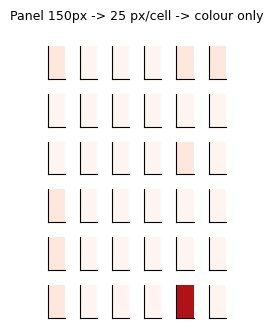

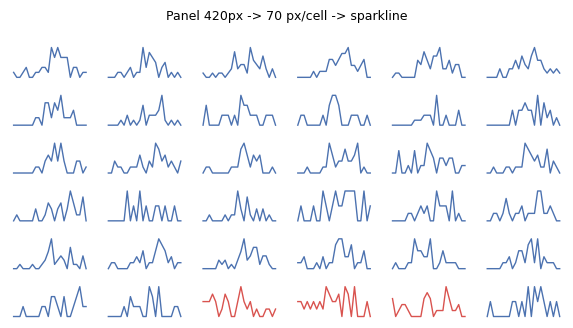

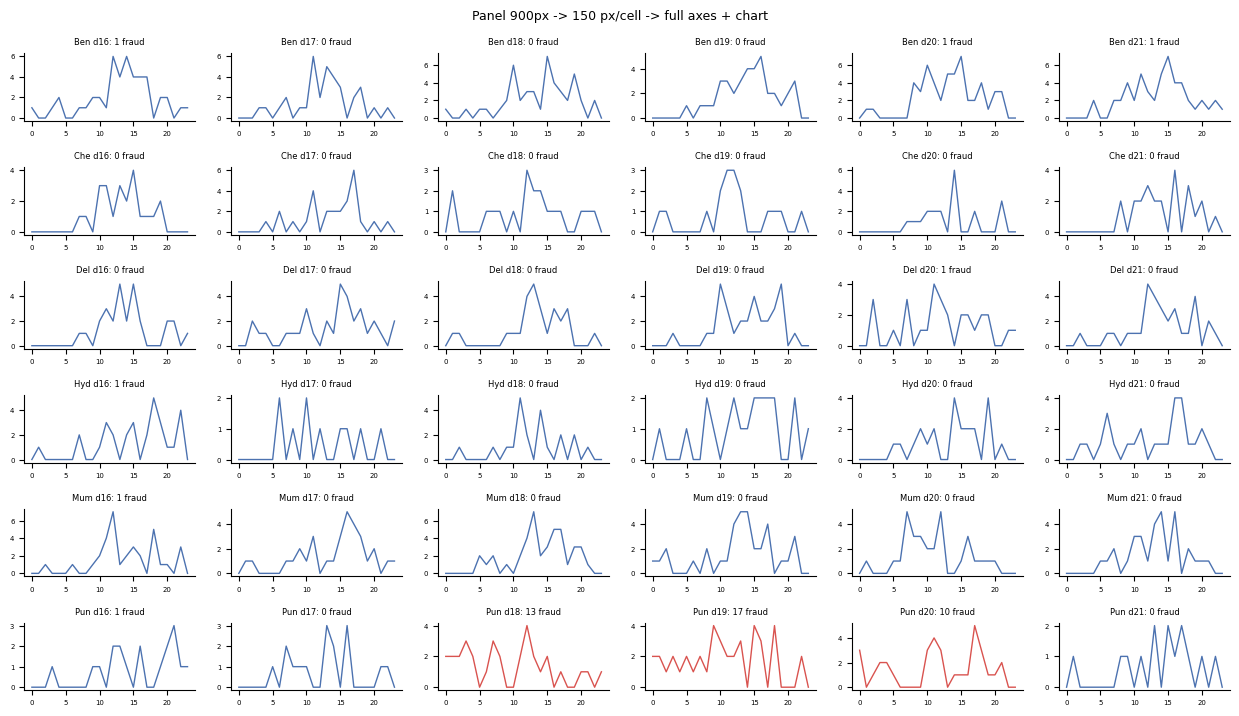

In [10]:
def representation(cell_px):
    return "full axes + chart" if cell_px >= 120 else ("sparkline" if cell_px >= 40 else ("colour only" if cell_px >= 4 else "hidden"))
for w in [2000, 4200]:
    print(f"panel {w} px / 25 cols = {w/25:.0f} px per cell -> {representation(w/25)}")
print(f"min width for full axes in all 25 cols = 120 x 25 = {120*25:,} px\n")

days, cities = list(range(16, 22)), sorted(tx.city.unique())
hourly = tx.groupby(["city", "day", "hour"]).size()
fraud = tx.groupby(["city", "day"]).is_fraud.sum()
for panel_px in [150, 420, 900]:
    cell_px = panel_px / len(days); rep = representation(cell_px)
    fig, axes = plt.subplots(len(cities), len(days), figsize=(panel_px / 72, 0.55 * len(cities) * (2.2 if rep.startswith("full") else 1)),
                             squeeze=False)
    for r, city in enumerate(cities):
        for c, day in enumerate(days):
            ax = axes[r, c]; f_ = fraud.get((city, day), 0)
            series = hourly.get((city, day), pd.Series(dtype=float)).reindex(range(24), fill_value=0)
            if rep == "colour only":
                ax.set_facecolor(plt.cm.Reds(min(f_ / 12, 1))); ax.set_xticks([]); ax.set_yticks([])
            else:
                ax.plot(series.values, color="#D9534F" if f_ >= 5 else "#4C72B0", lw=1)
                if rep == "sparkline": ax.set_xticks([]); ax.set_yticks([]); ax.axis("off")
                else: ax.tick_params(labelsize=5); ax.set_title(f"{city[:3]} d{day}: {f_} fraud", fontsize=6)
    fig.suptitle(f"Panel {panel_px}px -> {cell_px:.0f} px/cell -> {rep}", fontsize=9)
    plt.tight_layout(); plt.show()

## 10. Details-on-Demand and Tooltips  *(Slides 22–23)*

**What:** **Details-on-demand** keeps the main view uncluttered and shows extra attributes for an item only when asked
(click popup or fixed panel). **Tooltips** are the lightest form: hover reveals the item's attributes, disappearing when
the cursor moves. Great for single-item lookup — a poor way to build an overview.

**Why:** Below, the 300 highest-scoring transactions with a rich tooltip (hover any point). The main view shows only
position and colour; everything else is on demand.

In [11]:
top = tx.nlargest(300, "detector_score")
fig = px.scatter(top, x="timestamp", y="amount_inr", color="label", log_y=True,
                 color_discrete_map={"legitimate": "#4C72B0", "confirmed fraud": "#D9534F"},
                 hover_name="txn_id",
                 hover_data={"customer_id": True, "city": True, "merchant_category": True, "distance_from_home_km": ":.0f",
                             "detector_score": ":.3f", "label": False, "timestamp": "|%d %b %H:%M"},
                 title="Details-on-demand: hover any point for its full record", height=460)
fig.update_traces(marker_size=7)
fig.show()

## 11. Drill-Down  *(Slide 24)*

**What:** **Drill-down** navigates from a coarse aggregate through successive hierarchy levels to finer detail (its inverse
is **roll-up**); often driven by clicking a region. Works best when data has multi-level structure.

**Why:** Below, an interactive sunburst: **click a city** to drill down into its merchant categories, click the centre to
roll back up. Colour = fraud rate, so the drill-down path to the problem is visible from the top level.

In [12]:
agg = tx.groupby(["city", "merchant_category"]).agg(transactions=("txn_id", "size"), fraud=("is_fraud", "sum")).reset_index()
agg["fraud_rate_pct"] = agg.fraud / agg.transactions * 100
fig = px.sunburst(agg, path=[px.Constant("All cities"), "city", "merchant_category"], values="transactions",
                  color="fraud_rate_pct", color_continuous_scale="Reds", range_color=[0, 25],
                  hover_data={"fraud": True}, title="Drill-down: click a city to zoom in, click the centre to roll up", height=560)
fig.show()

## 12. Animated Transitions  *(Slide 25)*

**What:** Animated transitions interpolate marks from an old state to a new one instead of a jump cut, preserving **object
constancy** (the viewer keeps track of which mark is which). Heer & Robertson (2007): they help — as long as the amount of
simultaneous change stays limited.

**Why:** Below, one bubble per city, moving day by day (press ▶ or drag the slider): x = transactions, y = confirmed fraud.
Because each city glides rather than jumps, Pune's excursion on days 18–20 is easy to follow.

In [13]:
daily = tx.groupby(["day", "city"]).agg(transactions=("txn_id", "size"), fraud=("is_fraud", "sum"),
                                        volume_inr=("amount_inr", "sum")).reset_index()
fig = px.scatter(daily, x="transactions", y="fraud", size="volume_inr", color="city", animation_frame="day",
                 animation_group="city", range_x=[0, daily.transactions.max() * 1.1], range_y=[-1, daily.fraud.max() + 2],
                 size_max=40, title="Animated transition by day (object constancy: each city keeps its bubble)", height=500)
fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 600
fig.layout.updatemenus[0].buttons[0].args[1]["transition"]["duration"] = 450
fig.show()

## 13. Focus + Context: Degree-of-Interest and Elision  *(Slides 26, 32)*

**What:** Focus + context embeds detail about a **focus** and overview of the **context** in one view. Furnas's
degree-of-interest function **DOI(x) = I(x) − D(x, y)** combines an a-priori interest I with distance D from the current
focus y. **Elision**: high-DOI items in full detail, medium aggregated, low filtered out.

**Why:** Focus = day 19. Interest = detector score × 5; distance = |day − 19| / 2. Below: every transaction (unreadable) vs.
the DOI view — individual high-DOI transactions are drawn as points, everything else is elided into a daily-count
context strip.

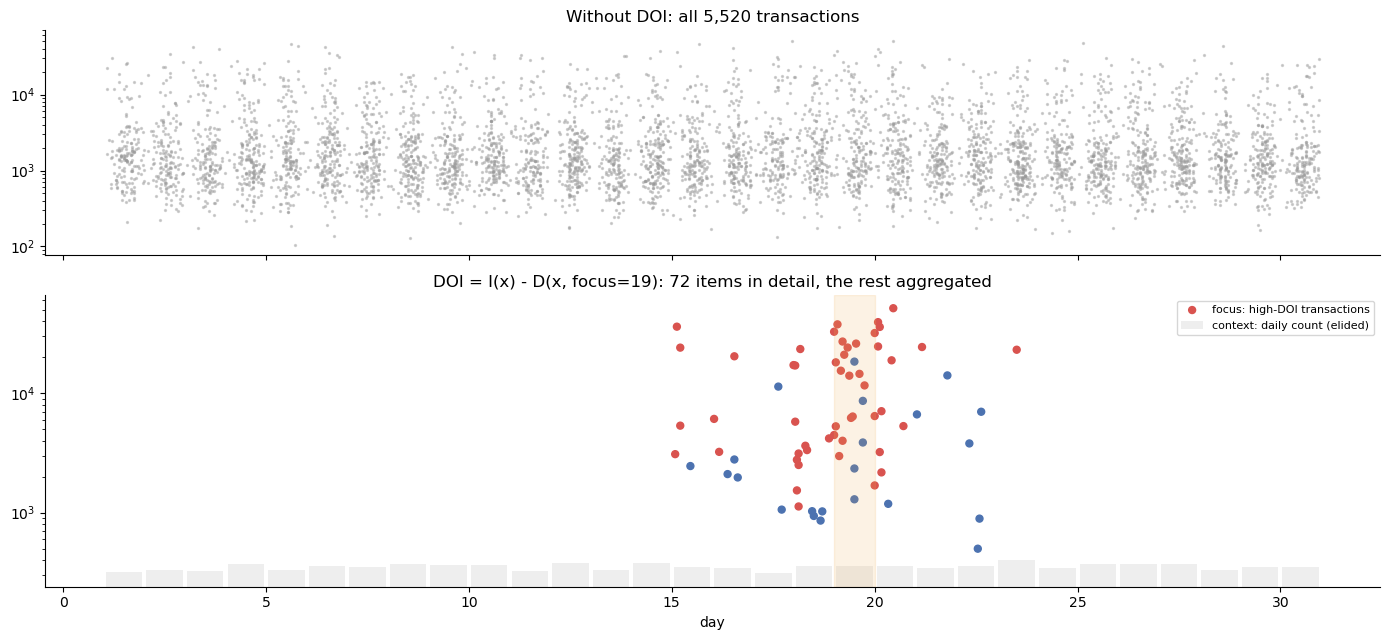

In [14]:
FOCUS = 19
tx["doi"] = tx.detector_score * 5 - (tx.day - FOCUS).abs() / 2
detail = tx[tx.doi > 2.5]
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
axes[0].scatter(tx.day + tx.hour / 24, tx.amount_inr, s=2, c="#999999", alpha=0.4); axes[0].set_yscale("log")
axes[0].set_title(f"Without DOI: all {len(tx):,} transactions")
ctx = tx.groupby("day").size()
axes[1].bar(ctx.index + 0.5, ctx.values / ctx.max() * 300 + 100, width=0.9, bottom=0, color="#eeeeee", label="context: daily count (elided)")
axes[1].scatter(detail.day + detail.hour / 24, detail.amount_inr, s=25, c=np.where(detail.is_fraud == 1, "#D9534F", "#4C72B0"),
                label="focus: high-DOI transactions")
axes[1].axvspan(FOCUS, FOCUS + 1, color="#f0ad4e", alpha=0.15); axes[1].set_yscale("log"); axes[1].set_xlabel("day")
axes[1].set_title(f"DOI = I(x) - D(x, focus={FOCUS}): {len(detail)} items in detail, the rest aggregated"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 14. Focus + Context: Fisheye Distortion  *(Slides 27–28)*

**What:** Distortion idioms compress context to magnify a focus within one view: **fisheye lens** (local, radial,
movable), hyperbolic geometry, 3-D perspective. Slide formula: magnification(d) = 1 + (m − 1)(r − d)/r for d ≤ r.
Numerical 4 (r = 15 px, m = 4, d = 6): 2.8×; a 3 px item → 8.4 px; magnification = 2× at d = 10 px.

**Why:** Numerical 4 in code, then a 1-D fisheye on the 30-day timeline: the focus days are magnified (wide bars), context
days compressed — all 30 days stay visible.

(a) magnification at d=6: 2.8x   (b) 3 px item -> 8.4 px
(c) solve 2 = 1 + 3(15 - d)/15 -> d = 10 px  (check: 2.0x)


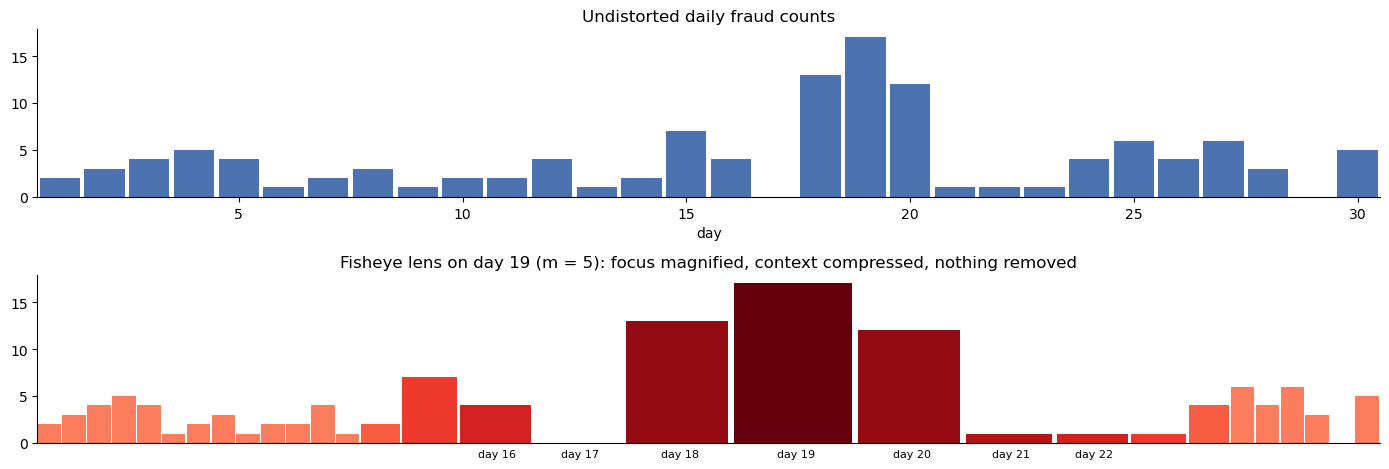

In [15]:
def magnification(d, r=15, m=4):
    return np.where(d <= r, 1 + (m - 1) * (r - d) / r, 1.0)
print(f"(a) magnification at d=6: {magnification(6):.1f}x   (b) 3 px item -> {3 * magnification(6):.1f} px")
print(f"(c) solve 2 = 1 + 3(15 - d)/15 -> d = {15 - 15 / 3:.0f} px  (check: {magnification(10):.1f}x)")

x = np.arange(1, 31) + 0.5
mag = magnification(np.abs(x - (FOCUS + 0.5)), r=6, m=5)
widths = mag / mag.sum() * 30                              # distorted widths, total length preserved
left = np.r_[0, np.cumsum(widths)[:-1]]
fr = tx.groupby("day").is_fraud.sum().reindex(range(1, 31), fill_value=0)
fig, axes = plt.subplots(2, 1, figsize=(14, 4.8))
axes[0].bar(np.arange(1, 31), fr.values, width=0.9, color="#4C72B0"); axes[0].set_title("Undistorted daily fraud counts")
axes[0].set_xlim(0.5, 30.5); axes[0].set_xlabel("day")
axes[1].bar(left, fr.values, width=widths * 0.95, align="edge", color=plt.cm.Reds(0.3 + 0.7 * mag / mag.max()))
for l_, w_, d_ in zip(left, widths, range(1, 31)):
    if w_ > 1.3: axes[1].text(l_ + w_ / 2, -1.5, f"day {d_}", ha="center", fontsize=8)
axes[1].set_xlim(0, 30); axes[1].set_xticks([]); axes[1].set_title(f"Fisheye lens on day {FOCUS} (m = 5): focus magnified, context compressed, nothing removed")
plt.tight_layout(); plt.show()

## 15. Overview First, Zoom and Filter, Details-on-Demand: An Interaction Sequence  *(Slides 29–30)*

**What:** Complex tasks are **chains** of interactions — the output of one step is the input of the next — so state must
persist and history/undo should exist. Shneiderman's mantra is the canonical chain: **overview first, zoom and filter,
then details-on-demand.**

**Why:** Below, the mantra executed as a three-step sequence on the transactions, each panel produced from the previous
step's selection.

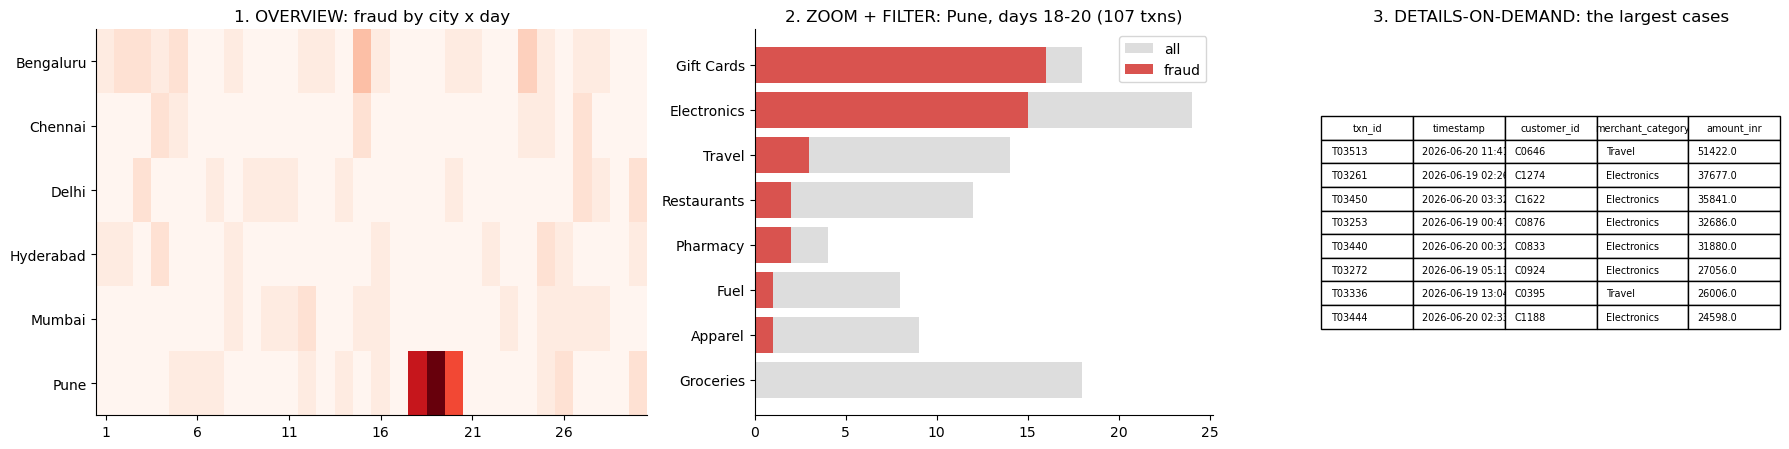

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
axes[0].imshow(heat, cmap="Reds", aspect="auto"); axes[0].set_yticks(range(len(heat))); axes[0].set_yticklabels(heat.index)
axes[0].set_xticks(range(0, 30, 5)); axes[0].set_xticklabels(heat.columns[::5]); axes[0].set_title("1. OVERVIEW: fraud by city x day")
step2 = tx[(tx.city == "Pune") & tx.day.between(18, 20)]
c2 = step2.groupby("merchant_category").is_fraud.agg(["sum", "size"]).sort_values("sum")
axes[1].barh(c2.index, c2["size"], color="#dddddd", label="all"); axes[1].barh(c2.index, c2["sum"], color="#D9534F", label="fraud")
axes[1].legend(); axes[1].set_title(f"2. ZOOM + FILTER: Pune, days 18-20 ({len(step2)} txns)")
step3 = step2[step2.is_fraud == 1].nlargest(8, "amount_inr")[["txn_id", "timestamp", "customer_id", "merchant_category", "amount_inr"]]
axes[2].axis("off"); tbl = axes[2].table(cellText=step3.astype(str).values, colLabels=step3.columns, loc="center", cellLoc="left")
tbl.auto_set_font_size(False); tbl.set_fontsize(7); tbl.scale(1, 1.3); axes[2].set_title("3. DETAILS-ON-DEMAND: the largest cases")
plt.tight_layout(); plt.show()

## 16. Interactive Temporal Visualization  *(Slide 33)*

**What:** Time-varying data uses the same idioms along the time axis: **time-range filtering** (a dynamic query on time),
**scrubbing**, **temporal drill-down** (month → day → hour) and an **overview + detail timeline**.

**Why:** Below, an interactive daily timeline with a **range slider** (an overview strip under the chart — drag its handles
to set the detail window) and **range-selector buttons** for quick temporal zoom.

In [17]:
hourly_ts = tx.set_index("timestamp").resample("h").agg({"txn_id": "size", "is_fraud": "sum"}).rename(columns={"txn_id": "transactions"})
fig = go.Figure()
fig.add_trace(go.Scatter(x=hourly_ts.index, y=hourly_ts.transactions, name="transactions / hour", line=dict(color="#9bb7d4")))
fig.add_trace(go.Bar(x=hourly_ts.index, y=hourly_ts.is_fraud * 5, name="confirmed fraud / hour (x5)", marker_color="#D9534F"))
fig.update_xaxes(rangeslider_visible=True, rangeselector=dict(buttons=[
    dict(count=1, label="1 day", step="day", stepmode="backward"), dict(count=3, label="3 days", step="day", stepmode="backward"),
    dict(count=7, label="1 week", step="day", stepmode="backward"), dict(step="all", label="all")]))
fig.update_layout(title="Overview + detail on a timeline: drag the slider handles below the chart", height=520)
fig.show()

## 17. Visual Analytics and Human-in-the-Loop Analysis  *(Slides 35–37)*

**What:** Visual analytics = *the science of analytical reasoning facilitated by interactive visual interfaces*
(Thomas & Cook 2005): automated analysis + interactive visualization, with the human steering both. Keim et al.'s pipeline:
data → (visualization path ∥ model path) → knowledge, iterated. **Human-in-the-loop**: users steer model parameters, see
results immediately, validate or challenge the model, and their corrections feed back into it.

**Why:** Below, the automated detector's score distribution for legitimate vs. fraud cases with the analyst's steerable
threshold; then we *close the loop*: train a new model on the first 15 days of analyst-confirmed labels and compare it with
the original detector on days 16–30.

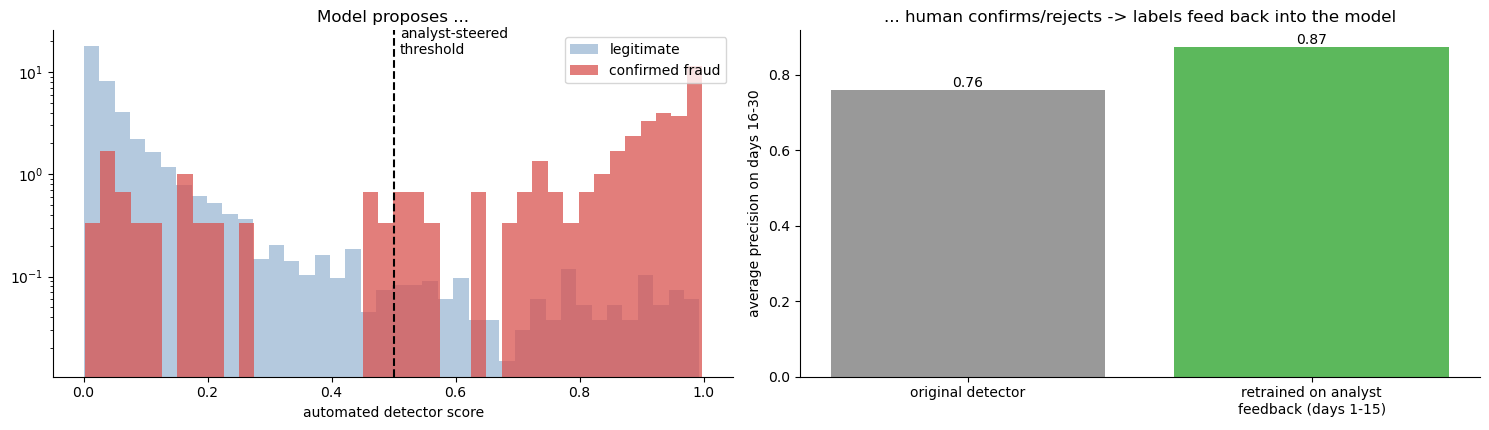

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for lab, col in [(0, "#9bb7d4"), (1, "#D9534F")]:
    axes[0].hist(tx.detector_score[tx.is_fraud == lab], bins=40, alpha=0.75, color=col, density=True,
                 label="legitimate" if lab == 0 else "confirmed fraud")
axes[0].axvline(0.5, color="black", ls="--"); axes[0].text(0.51, axes[0].get_ylim()[1] * 0.8, "analyst-steered\nthreshold")
axes[0].set_xlabel("automated detector score"); axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("Model proposes ...")

feat = pd.get_dummies(tx[["merchant_category", "city"]]).assign(
    log_amount=np.log(tx.amount_inr), log_dist=np.log1p(tx.distance_from_home_km), night=tx.night.astype(int))
train, test = tx.day <= 15, tx.day > 15
model = LogisticRegression(max_iter=2000).fit(feat[train], tx.is_fraud[train])
new_score = model.predict_proba(feat[test])[:, 1]
ap_old = average_precision_score(tx.is_fraud[test], tx.detector_score[test]); ap_new = average_precision_score(tx.is_fraud[test], new_score)
axes[1].bar(["original detector", "retrained on analyst\nfeedback (days 1-15)"], [ap_old, ap_new], color=["#999999", "#5cb85c"])
for i, v in enumerate([ap_old, ap_new]): axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom")
axes[1].set_ylabel("average precision on days 16-30"); axes[1].set_title("... human confirms/rejects -> labels feed back into the model")
plt.tight_layout(); plt.show()

## 18. Exploratory Analysis and Pattern Discovery by Reordering  *(Slides 38–39)*

**What:** **Exploratory** analysis is open-ended (Munzner's *discover* goal; Tukey) — find what's interesting before asking
formally. **Pattern discovery** finds unknown trends, clusters, correlations; **reordering/sorting** is one of the most
powerful pattern-finding interactions because it engages the visual system's fast pattern detection.

**Why:** Below, a city × day fraud-rate matrix in alphabetical/calendar order vs. rows and columns **reordered** by their
totals — the "ring" pattern consolidates into one corner.

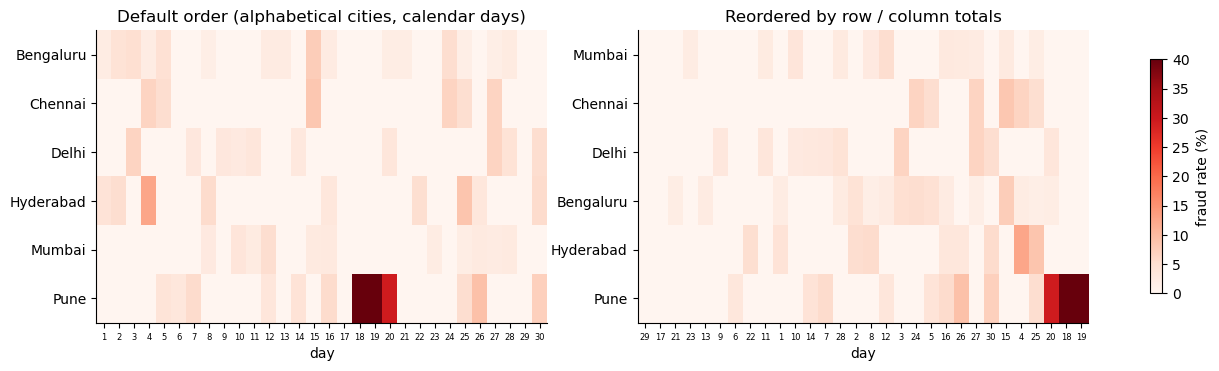

In [19]:
rate = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="mean", fill_value=0) * 100
reordered = rate.loc[rate.sum(axis=1).sort_values().index, rate.sum(axis=0).sort_values().index]
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for ax, M, t in zip(axes, [rate, reordered], ["Default order (alphabetical cities, calendar days)", "Reordered by row / column totals"]):
    im = ax.imshow(M, cmap="Reds", aspect="auto", vmax=40)
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index); ax.set_xticks(range(30)); ax.set_xticklabels(M.columns, fontsize=6)
    ax.set_title(t); ax.set_xlabel("day")
plt.colorbar(im, ax=axes, label="fraud rate (%)", shrink=0.8); plt.show()

## 19. Anomaly Detection: Precision, Recall and F1  *(Slides 40–41)*

**What:** Anomaly detection finds items deviating from the norm; a typical hybrid has an automated detector propose
candidates and an analyst confirm them. Quality metrics: **precision = TP/(TP+FP)**, **recall = TP/(TP+FN)**,
**F1 = 2PR/(P+R)**. Numerical 5: TP = 42, FP = 5, FN = 8 → P = 0.894, R = 0.84, F1 ≈ 0.866.

**Why:** Numerical 5 in code; then the precision–recall trade-off of our detector as the analyst moves the threshold —
the curve an analyst steers along.

Numerical 5: precision = 42/47 = 0.894, recall = 42/50 = 0.84, F1 = 0.866



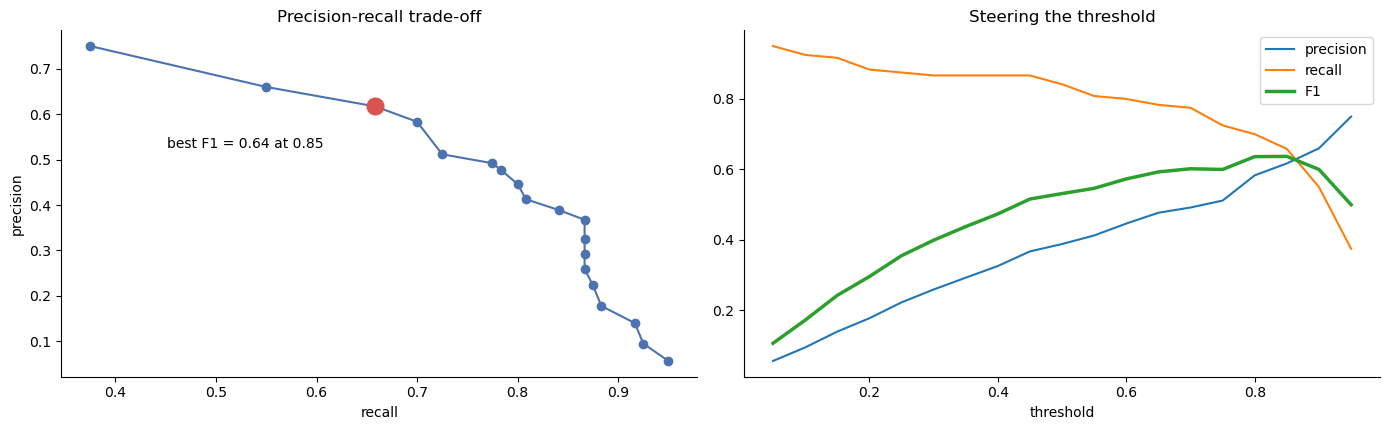

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
3,0.20,596,106,490,14,0.178,0.883,0.296
6,0.35,355,104,251,16,0.293,0.867,0.438
9,0.50,260,101,159,19,0.388,0.842,0.532
12,0.65,197,94,103,26,0.477,0.783,0.593
15,0.80,144,84,60,36,0.583,0.700,0.636
18,0.95,60,45,15,75,0.750,0.375,0.500


In [20]:
def prf(tp, fp, fn):
    p, r = tp / (tp + fp), tp / (tp + fn)
    return p, r, 2 * p * r / (p + r)
p, r, f1 = prf(42, 5, 50 - 42)
print(f"Numerical 5: precision = 42/47 = {p:.3f}, recall = 42/50 = {r:.2f}, F1 = {f1:.3f}\n")

rows = []
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum()); fp = int((flag & (tx.is_fraud == 0)).sum()); fn = int((~flag & (tx.is_fraud == 1)).sum())
    p_, r_, f_ = prf(tp, fp, fn) if tp else (0, 0, 0)
    rows.append(dict(threshold=th, alerts=tp + fp, TP=tp, FP=fp, FN=fn, precision=p_, recall=r_, F1=f_))
pr = pd.DataFrame(rows)
best = pr.loc[pr.F1.idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot(pr.recall, pr.precision, "o-", color="#4C72B0"); axes[0].plot(best.recall, best.precision, "o", ms=12, color="#D9534F")
axes[0].annotate(f"best F1 = {best.F1:.2f} at {best.threshold}", (best.recall, best.precision), xytext=(-150, -30), textcoords="offset points")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall trade-off")
axes[1].plot(pr.threshold, pr.precision, label="precision"); axes[1].plot(pr.threshold, pr.recall, label="recall")
axes[1].plot(pr.threshold, pr.F1, label="F1", lw=2.5); axes[1].set_xlabel("threshold"); axes[1].legend(); axes[1].set_title("Steering the threshold")
plt.tight_layout(); plt.show()
pr.round(3).iloc[::3]

## 20. Hypothesis Generation and Testing (and Confirmation Bias)  *(Slides 42–43)*

**What:** **Generation**: a visual pattern + domain knowledge → a candidate explanation (keep several competing ones).
**Testing**: confirm visually (re-encode to show the pattern directly), statistically, and by **searching for
counter-examples**. Confirmation bias is the risk — a good tool makes disconfirming evidence as easy to find as confirming
evidence.

**Why:** Hypothesis from Sections 15/18: *"a fraud ring operated in Pune on days 18–20."* Competing hypothesis: *"Pune just
has more fraud in general."* Below: a statistical test plus two counter-example searches.

Fraud rate in Pune days 18-20: 37.4%  vs everywhere else: 1.5%  (chi-square p = 1.1e-136)
Counter-example search 1 -- Pune on OTHER days: 1.9% (similar to baseline -> not 'Pune in general')
Counter-example search 2 -- OTHER cities on days 18-20: 0.4% (baseline -> not 'those days in general')


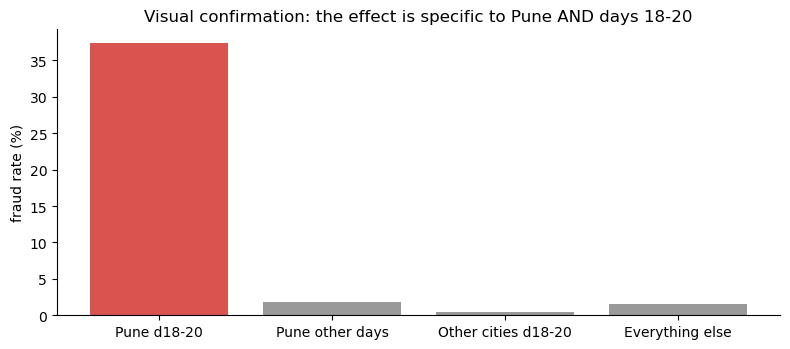

In [21]:
from scipy.stats import chi2_contingency
ring = (tx.city == "Pune") & tx.day.between(18, 20)
table = pd.crosstab(ring, tx.is_fraud)
chi2, pval, _, _ = chi2_contingency(table)
print(f"Fraud rate in Pune days 18-20: {tx.is_fraud[ring].mean():.1%}  vs everywhere else: {tx.is_fraud[~ring].mean():.1%}"
      f"  (chi-square p = {pval:.1e})")
pune_other = tx[(tx.city == "Pune") & ~tx.day.between(18, 20)]
others_same = tx[(tx.city != "Pune") & tx.day.between(18, 20)]
print(f"Counter-example search 1 -- Pune on OTHER days: {pune_other.is_fraud.mean():.1%} (similar to baseline -> not 'Pune in general')")
print(f"Counter-example search 2 -- OTHER cities on days 18-20: {others_same.is_fraud.mean():.1%} (baseline -> not 'those days in general')")

fig, ax = plt.subplots(figsize=(8, 3.6))
grp = {"Pune d18-20": tx.is_fraud[ring].mean(), "Pune other days": pune_other.is_fraud.mean(),
       "Other cities d18-20": others_same.is_fraud.mean(), "Everything else": tx.is_fraud[~ring & (tx.city != "Pune") & ~tx.day.between(18, 20)].mean()}
ax.bar(grp.keys(), np.array(list(grp.values())) * 100, color=["#D9534F", "#999999", "#999999", "#999999"])
ax.set_ylabel("fraud rate (%)"); ax.set_title("Visual confirmation: the effect is specific to Pune AND days 18-20")
plt.tight_layout(); plt.show()

## 21. Sensemaking, Information Foraging and Scented Widgets  *(Slides 44–47)*

**What:** **Sensemaking** (Pirolli & Card 2005): a **foraging loop** (search & filter → read & extract → shoebox → evidence
file) and a **synthesis loop** (schema → hypotheses → presentation). **Information foraging** (Pirolli 2007): analysts follow
**information scent** between patches; a patch yields diminishing returns. **Scented widgets** (Willett et al. 2007) embed
small visual cues in controls. Numerical 6: V(t) = 10√t → dV/dt = 5/√t = 2.5 at t = 4; leave when the rate falls to the
average 2 units/s → t = 6.25 s; scent saves the 4 s of wasted foraging per rejected patch.

**Why:** Numerical 6 in code and plotted; then a **scented filter widget**: a category list where each option carries its
count and a mini fraud-rate bar, so the analyst knows which patch to open *before* opening it.

(a) dV/dt at t=4: 2.50 units/s   (b) leave when 5/sqrt(t) = 2 -> t = 6.25 s   (c) time saved per rejected patch: 4 s


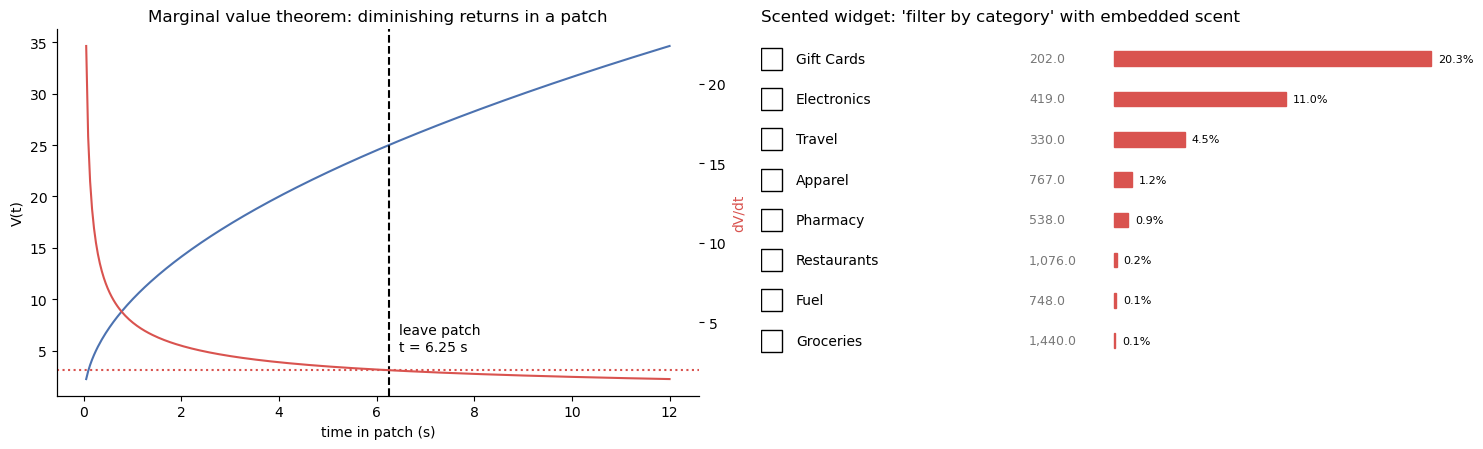

In [22]:
t = np.linspace(0.05, 12, 300); V = 10 * np.sqrt(t); rate_ = 5 / np.sqrt(t)
t_leave = (5 / 2) ** 2
print(f"(a) dV/dt at t=4: {5/np.sqrt(4):.2f} units/s   (b) leave when 5/sqrt(t) = 2 -> t = {t_leave:.2f} s   (c) time saved per rejected patch: 4 s")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].plot(t, V, color="#4C72B0", label="value gained V(t)"); ax2 = axes[0].twinx()
ax2.plot(t, rate_, color="#D9534F", label="instantaneous rate dV/dt"); ax2.axhline(2, color="#D9534F", ls=":")
axes[0].axvline(t_leave, color="black", ls="--"); axes[0].text(t_leave + 0.2, 5, f"leave patch\nt = {t_leave} s")
axes[0].set_xlabel("time in patch (s)"); axes[0].set_ylabel("V(t)"); ax2.set_ylabel("dV/dt", color="#D9534F")
axes[0].set_title("Marginal value theorem: diminishing returns in a patch")

scent = tx.groupby("merchant_category").agg(n=("txn_id", "size"), rate=("is_fraud", "mean")).sort_values("rate", ascending=False)
axes[1].axis("off"); axes[1].set_title("Scented widget: 'filter by category' with embedded scent", loc="left")
for i, (cat, r_) in enumerate(scent.iterrows()):
    y = 1 - (i + 1) * 0.11
    axes[1].add_patch(plt.Rectangle((0.0, y), 0.03, 0.06, transform=axes[1].transAxes, fill=False))
    axes[1].text(0.05, y + 0.03, f"{cat}", transform=axes[1].transAxes, va="center", fontsize=10)
    axes[1].text(0.38, y + 0.03, f"{r_.n:,}", transform=axes[1].transAxes, va="center", fontsize=9, color="#777777")
    axes[1].add_patch(plt.Rectangle((0.5, y + 0.01), 0.45 * r_.rate / scent.rate.max(), 0.04, transform=axes[1].transAxes, color="#D9534F"))
    axes[1].text(0.5 + 0.45 * r_.rate / scent.rate.max() + 0.01, y + 0.03, f"{r_.rate:.1%}", transform=axes[1].transAxes, va="center", fontsize=8)
plt.tight_layout(); plt.show()

## 22. Iterative Analytical Reasoning, Provenance and a Visual-Analytics Workflow  *(Slides 48–51)*

**What:** Analytical reasoning is **cyclic**: overview → filter/select → drill down → revise hypothesis → repeat.
**History / provenance** lets an analyst retrace, justify and resume. At team scale, a **workflow** runs:
ingest & clean → automated analysis → visual checkpoint → decision & reporting, with **confirmed/rejected cases fed back
to the model**.

**Why:** Below, a tiny provenance log records each interaction of this notebook's investigation, and the operational
triage funnel shows how the workflow narrows 5,520 transactions to a reviewable shortlist.

,step,action,items,note
0,1,overview,5520,"city x day heatmap: hotspot in Pune, days 18-20"
1,2,filter,107,hypothesis H1: fraud ring
2,3,drill-down,42,ring targets electronics / gift cards
3,4,details,31,confirmed cases exported to investigations
4,5,test,593,counter-example: Pune other days is baseline -...


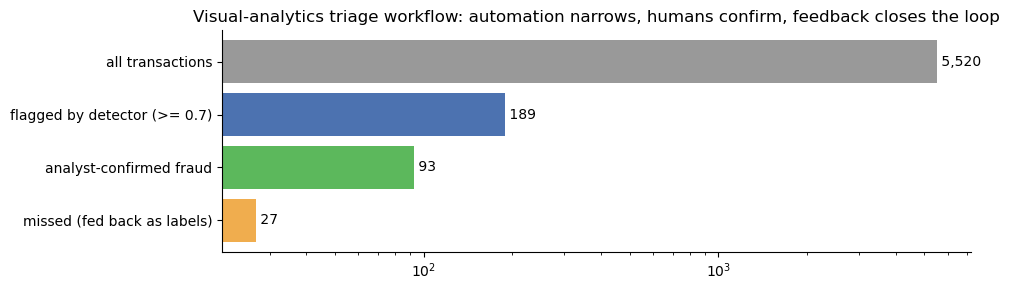

In [23]:
log = []
def step(action, data, note):
    log.append({"step": len(log) + 1, "action": action, "items": len(data), "note": note}); return data

s = step("overview", tx, "city x day heatmap: hotspot in Pune, days 18-20")
s = step("filter", s[(s.city == "Pune") & s.day.between(18, 20)], "hypothesis H1: fraud ring")
s = step("drill-down", s[s.merchant_category.isin(["Electronics", "Gift Cards"])], "ring targets electronics / gift cards")
s = step("details", s[s.is_fraud == 1], "confirmed cases exported to investigations")
s = step("test", tx[(tx.city == "Pune") & ~tx.day.between(18, 20)], "counter-example: Pune other days is baseline -> H1 holds")
display(pd.DataFrame(log))

flag = tx.detector_score >= 0.7
funnel = {"all transactions": len(tx), "flagged by detector (>= 0.7)": int(flag.sum()),
          "analyst-confirmed fraud": int((flag & (tx.is_fraud == 1)).sum()), "missed (fed back as labels)": int((~flag & (tx.is_fraud == 1)).sum())}
fig, ax = plt.subplots(figsize=(10, 3))
ax.barh(list(funnel)[::-1], list(funnel.values())[::-1], color=["#f0ad4e", "#5cb85c", "#4C72B0", "#999999"]); ax.set_xscale("log")
for i, v in enumerate(list(funnel.values())[::-1]): ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Visual-analytics triage workflow: automation narrows, humans confirm, feedback closes the loop")
plt.tight_layout(); plt.show()

## Summary: Technique -> When to Use It

| Technique | Solves | Use it when... |
|---|---|---|
| Brushing + linked highlighting | Patterns invisible in any single view | Several coordinated views of the same items |
| Dynamic queries (sliders) | Not knowing what range to ask for | Browsing an unfamiliar dataset; needs < 0.1 s feedback |
| Highlight by outline / size | Colour highlight hides colour coding | Selection on views that already use colour |
| Geometric vs. semantic zoom | Fixed representation at every scale | Dense grids / timelines viewed at many sizes |
| Tooltips / details-on-demand | Clutter from showing every attribute | Single-item lookup on top of an overview |
| Drill-down / roll-up | Multi-level data (city → category) | Hierarchical aggregates |
| Animated transitions | Losing track of items after a change | Re-sorting, filtering, stepping through time |
| DOI elision / fisheye | Need focus detail without losing context | Long timelines, big trees and networks |
| Overview → zoom & filter → details | Unstructured exploration | The default scaffold for any interactive tool |
| Range slider timeline | Long time series | Time-window selection with an overview |
| Reordering | Hidden structure in matrices / tables | Pattern discovery |
| Precision / recall / F1 + threshold steering | Judging an automated detector | Human-in-the-loop anomaly triage |
| Counter-example search | Confirmation bias | Every hypothesis test |
| Scented widgets | Blind foraging | Filters over unfamiliar categories |
| Provenance log + feedback loop | Unrepeatable analysis, stale models | Team workflows and production visual analytics |

**Core principle:** interaction turns visualization into a *process* — each cycle of view → interpret → act should be
cheap, fast and recorded, with the human steering and the automation scaling.